# Lab 7 Part 2 & 3

Disclaimer: AI was used for lab code and results were verified

### 2.1)

In [1]:
import warnings
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")

col_names = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv('../../data/glass.csv', header=None, names=col_names)
class_names = {1: 'building_float', 2: 'building_nonfloat', 3: 'vehicle_float',
               5: 'containers', 6: 'tableware', 7: 'headlamps'}
features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

X = glass[features]
y = glass['type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

In [2]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import confusion_matrix

classes = np.sort(y_train.unique())
labels = [class_names[c] for c in classes]
oxides = [f for f in features if f != "RI"]
eps = np.finfo(float).eps

a)

In [3]:
X.describe().loc[["mean", "std", "min", "max"]]

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000


b)

In [4]:
counts = pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).sort_index()
counts.index = labels
counts

,train,test
building_float,56,14
building_nonfloat,61,15
vehicle_float,14,3
containers,10,3
tableware,7,2
headlamps,23,6


The building glasses are more common that vehice, containers, tableware, or headlamps with tableware being especially uncommon

c)

In [5]:
majority = y_train.mode()[0]
print("Most common class:", class_names[majority])
print("Accuracy:", (y_train == majority).mean())

Most common class: building_nonfloat
Accuracy: 0.3567251461988304


d) 

In [6]:
props = y_train.value_counts(normalize=True).sort_index()
P_base = np.tile(props.values, (len(y_train), 1))
base_rate = log_loss(y_train, P_base, labels=classes)
print("Base-rate log loss:", base_rate, ", ln 6 =", np.log(6))

Base-rate log loss: 1.5048600948064486 , ln 6 = 1.791759469228055


e) 

- The base rate log loss is lower than ln 6 (the uniform log los) because the proportion of classes is not equal. There are more observations of building glass than the rest of the classes so the base rate log loss will be lower than guessing classes uniformly. 

### 2.2)

a)

In [7]:
glass[oxides].sum(axis=1).describe()

count    214.000000
mean      99.874299
std        0.122126
min       99.020000
25%       99.810000
50%       99.890000
75%       99.960000
max      100.100000
dtype: float64

The sum of the oxides across each row add up to between 99 and 100 perfectly in every example. That means they're nearly perfectly collinear when including them in a regression model which will increase the variance

b)

In [8]:
pipe_no_penalty = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(C=np.inf, max_iter=50000)),
])

res = cross_validate(pipe_no_penalty, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
ll_none = -res["test_neg_log_loss"].mean()
acc_none = res["test_accuracy"].mean()
print("CV log loss:", ll_none, ", CV accuracy:", acc_none)

pipe_no_penalty.fit(X_train, y_train)
coef_none = pd.DataFrame(pipe_no_penalty[-1].coef_.T, index=features, columns=labels)
coef_none.round(2)

CV log loss: 4.175452160904577 , CV accuracy: 0.626218487394958


,building_float,building_nonfloat,vehicle_float,containers,tableware,headlamps
RI,-14.88,-13.61,-20.40,-13.98,27.60,35.26
Na,-27.01,-31.74,-20.31,-26.64,49.60,56.10
Mg,-7.22,-18.82,5.63,-14.18,13.42,21.17
Al,-15.87,-16.40,-11.33,-7.43,28.98,22.04
Si,-19.71,-24.63,-15.83,-17.17,30.22,47.11
K,3.50,-0.11,6.40,2.16,-43.38,31.43
Ca,-1.24,-11.67,15.28,-2.12,-7.75,7.50
Ba,3.61,-0.87,6.55,2.29,-36.02,24.43
Fe,15.38,15.62,14.99,15.11,-45.40,-15.69


c)

In [9]:
vif = sm.add_constant(X_train)
pd.Series([variance_inflation_factor(vif.values, i) for i in range(1, vif.shape[1])],
          index=features, name="VIF").round(1)

RI     11.5
Na     90.5
Mg    291.9
Al     33.9
Si     83.4
K      45.4
Ca    335.0
Ba     38.5
Fe      1.4
Name: VIF, dtype: float64

It looks like the Oxides are very correlated with each other except for Fe. In regards to the coefficients calculated in B we now have much less confidence in their value (larger SD) and they may not be fully representing the true effect that the variables have on type.

d)

- Well accuracy only considers if the highest probability class is the correct predicted class. Log loss considers the probability assigned to the correct class so high confidence wrong preditions will create a pretty high log loss even though it correctly identifies more classes

### 2.3)

a) 

In [10]:
c = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
penalties = {"ridge": "l2","lasso": "l1"}
rows = []

for name, penalty in penalties.items():
    for C in c:
        solver = "lbfgs" if penalty == "l2" else "saga"
        pipe = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(
            C=C, penalty=penalty, solver=solver, max_iter=50000))])

        res = cross_validate( pipe, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
        pipe.fit(X_train, y_train)
        rows.append({"penalty": name, "C": C, "ll": -res["test_neg_log_loss"].mean(),
                     "ll_sd": res["test_neg_log_loss"].std(), "acc": res["test_accuracy"].mean(),
                     "nonzero": int((pipe[-1].coef_ != 0).sum())})

results = pd.DataFrame(rows)

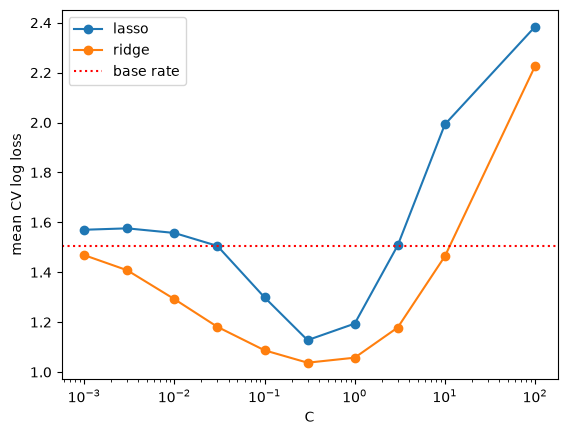

Lowest CV log loss: penalty       ridge
C               0.3
ll         1.037413
ll_sd      0.156369
acc        0.597143
nonzero          54
Name: 5, dtype: object 

1-SE rule selects: penalty       ridge
C               0.1
ll          1.08711
ll_sd      0.111381
acc        0.556303
nonzero          54
Name: 4, dtype: object


In [11]:
for name, df in results.groupby("penalty"):
    plt.plot(df["C"], df["ll"], marker="o", label=name)
plt.axhline(base_rate, color="red", ls=":", label="base rate")
plt.xscale("log"); plt.xlabel("C"); plt.ylabel("mean CV log loss"); plt.legend(); plt.show()

best = results.loc[results["ll"].idxmin()]
se = best["ll_sd"] / np.sqrt(5)
within = results[results["ll"] <= best["ll"] + se]
chosen = within.sort_values(["nonzero", "C"]).iloc[0]

print("Lowest CV log loss:", best, "\n")
print("1-SE rule selects:", chosen)

b)

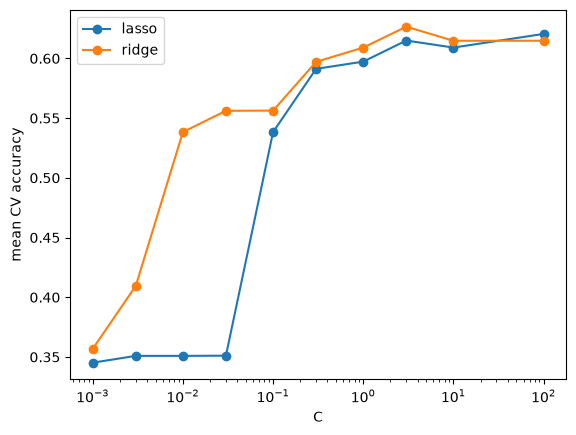

Highest accuracy:
 penalty       ridge
C               3.0
ll         1.178427
ll_sd      0.432264
acc        0.626555
nonzero          54
Name: 7, dtype: object 

Part a lowest-log-loss model:
 penalty       ridge
C               0.3
ll         1.037413
acc        0.597143
Name: 5, dtype: object


In [12]:
for name, df in results.groupby("penalty"):
    plt.plot(df["C"], df["acc"], marker="o", label=name)
plt.xscale("log"); plt.xlabel("C"); plt.ylabel("mean CV accuracy"); plt.legend(); plt.show()

print("Highest accuracy:\n", results.loc[results["acc"].idxmax()], "\n")
print("Part a lowest-log-loss model:\n", best[["penalty", "C", "ll", "acc"]])

c)

In [13]:
results[results["C"] >= 10][["penalty", "C", "ll", "acc"]]

,penalty,C,ll,acc
8,ridge,10.0,1.464036,0.614790
9,ridge,100.0,2.225997,0.614790
18,lasso,10.0,1.992496,0.609076
19,lasso,100.0,2.384012,0.620504


Increasing C makes the penalty smaller moving it towards the unpenalized model in Q2, so it doesn't really shrink those collinear variables much at all. The reason the log loss is worse than the base rate log loss is better than the high-C models is because the high-C models barely affect the coefficients and they make brazenly confident incorrect picks because of it. 

d)

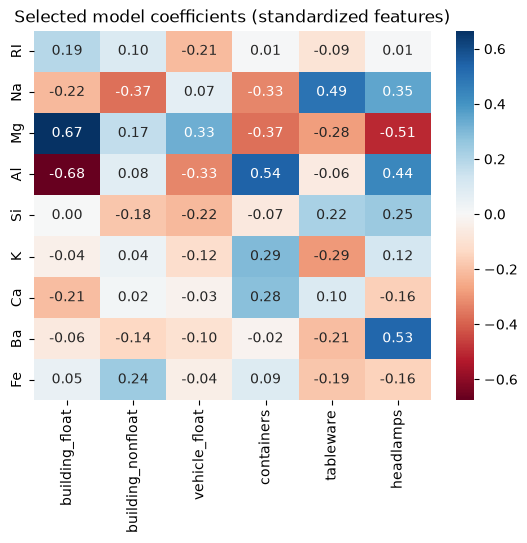

Nonzero for only one class: []


In [14]:
sel_model = Pipeline([("scale", StandardScaler()),
    ("model", LogisticRegression(C=chosen["C"], penalty=penalties[chosen["penalty"]], max_iter=50000)),
])
sel_model.fit(X_train, y_train)
coef_sel = pd.DataFrame(sel_model[-1].coef_.T, index=features, columns=labels)

sns.heatmap(coef_sel, annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title("Selected model coefficients (standardized features)")
plt.show()

print("Nonzero for only one class:", list(coef_sel.index[(coef_sel != 0).sum(axis=1) == 1]))

It looks like none of the features have a nonzero coefficient for only one class since the chosen model was Ridge, which rarely zeroes out coefficients

e)

In [25]:
diff = coef_sel.loc["Ba", "headlamps"] - coef_sel.loc["Ba", "building_float"]
print('Ba affect on headlamps vs building floats: ', diff, np.exp(diff))

diff1 = coef_sel.loc["Mg", "headlamps"] - coef_sel.loc["Ba", "building_float"]
print('Mg affect on headlamps vs building floats: ', diff1, np.exp(diff1))

Ba affect on headlamps vs building floats:  0.5980672883609861 1.8186005711338034
Mg affect on headlamps vs building floats:  -0.4412664609475125 0.6432212903816148


### 2.4)

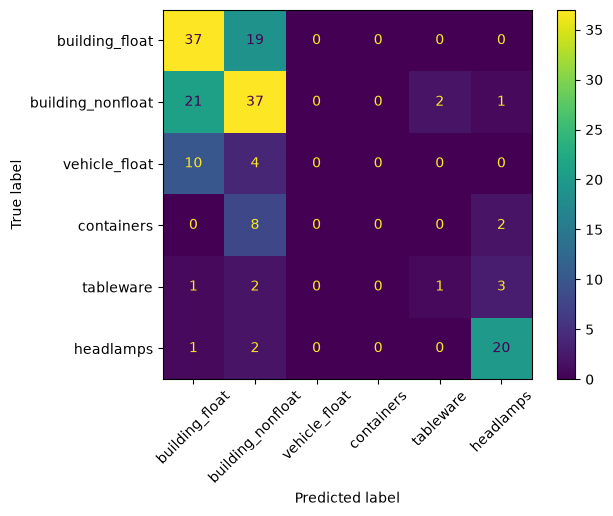

,precision,recall
building_float,0.529,0.661
building_nonfloat,0.514,0.607
vehicle_float,0.000,0.000
containers,0.000,0.000
tableware,0.333,0.143
headlamps,0.769,0.870


In [15]:
pred_logit = cross_val_predict(sel_model, X_train, y_train, cv=cv)

ConfusionMatrixDisplay.from_predictions(y_train, pred_logit, display_labels=labels, xticks_rotation=45)
plt.show()
pd.DataFrame({
    "precision": precision_score(y_train, pred_logit, average=None),
    "recall": recall_score(y_train, pred_logit, average=None),}, index=labels).round(3)

a)

- The logistic doesn't correctly predict vehicle_float or containers correctly once, and also struggles with tableware but that has less than half of the observations of every other class

b)

- Most are predicted as building float with the remainder being predicted as building nonfloat. I'm assuming that the float processing (whether it's a feature of the glass before the crime or if that's a test it undergoes after, I don't know) makes the vehicle and building glass nearly indistinguishable, which is why the model incorrectly predicts it.

# Part 3)

### 3.1)

a & b)

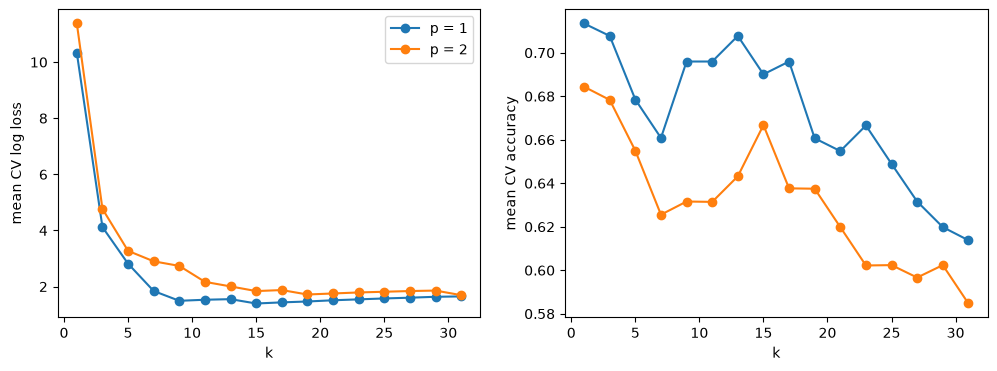

a) Lowest log loss:
 k      15.000000
p       1.000000
ll      1.396730
acc     0.690084
Name: 7, dtype: float64 

b) Highest accuracy:
 k       1.000000
p       1.000000
ll     10.328475
acc     0.713445
Name: 0, dtype: float64


In [16]:
rows = []
for p in [1, 2]:
    for k in range(1, 32, 2):
        pipe = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k, p=p))])
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
        rows.append({"k": k, "p": p, "ll": -res["test_neg_log_loss"].mean(), "acc": res["test_accuracy"].mean()})
knn_results = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for p, df in knn_results.groupby("p"):
    axes[0].plot(df["k"], df["ll"], marker="o", label=f"p = {p}")
    axes[1].plot(df["k"], df["acc"], marker="o", label=f"p = {p}")
axes[0].set(xlabel="k", ylabel="mean CV log loss"); axes[1].set(xlabel="k", ylabel="mean CV accuracy")
axes[0].legend(); plt.show()

best_knn_row = knn_results.loc[knn_results["ll"].idxmin()]
print("a) Lowest log loss:\n", best_knn_row, "\n")
print("b) Highest accuracy:\n", knn_results.loc[knn_results["acc"].idxmax()])

In [17]:
knn_best = Pipeline([("scale", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=int(best_knn_row["k"]), p=int(best_knn_row["p"])))])

- Going off of accuracy alone, I would've picked k = 1 since it has the highest accuracy for both Manhattan and Euclidian distances. For p I choose 1 (manhattan) since it's accuracy is above 2 for every k tested.
- The log loss is high for k = 1 is high because the confidence in each pick is high, making incorrect picks cost a lot in log loss. Choosing k=1 would be a poor choice since the log loss is very high, instead it would be better near the elbow in the log loss graph (around 5-10).

### 3.2)

a & b)

In [18]:
prob = cross_val_predict(knn_best, X_train, y_train, cv=cv, method="predict_proba")
p_true = prob[np.arange(len(y_train)), np.searchsorted(classes, y_train)]   # probability of the TRUE class
zero = p_true == 0

print("Fragments with probability exactly 0:", zero.sum())
print(y_train[zero].map(class_names).value_counts())

loss_each = -np.log(eps)
total = -np.log(np.maximum(p_true, eps)).sum()
print("Each zero adds:", f"{loss_each:.3f}")
print("% of total log loss from zeros:", f"{(100 * zero.sum() * loss_each / total):.3f}")
print("Mean log loss of remaining fragments:", f"{(-np.log(p_true[~zero]).mean()):.3f}")

Fragments with probability exactly 0: 3
type
headlamps     2
containers    1
Name: count, dtype: int64
Each zero adds: 36.044
% of total log loss from zeros: 45.197
Mean log loss of remaining fragments: 0.780


### 3.3)

a)

In [19]:
pred_knn = cross_val_predict(knn_best, X_train, y_train, cv=cv)
pd.DataFrame({"logistic": [chosen["ll"], chosen["acc"]],
              "KNN": [best_knn_row["ll"], best_knn_row["acc"]],
              }, index=["CV log loss", "CV accuracy"]).round(3)

,logistic,KNN
CV log loss,1.087,1.397
CV accuracy,0.556,0.690


The logistic model has the lower CV log loss

In [20]:
pd.DataFrame({
    "logistic": recall_score(y_train, pred_logit, average=None),
    "KNN": recall_score(y_train, pred_knn, average=None),
}, index=labels).round(3)

,logistic,KNN
building_float,0.661,0.964
building_nonfloat,0.607,0.721
vehicle_float,0.000,0.000
containers,0.000,0.200
tableware,0.143,0.000
headlamps,0.870,0.783


b)

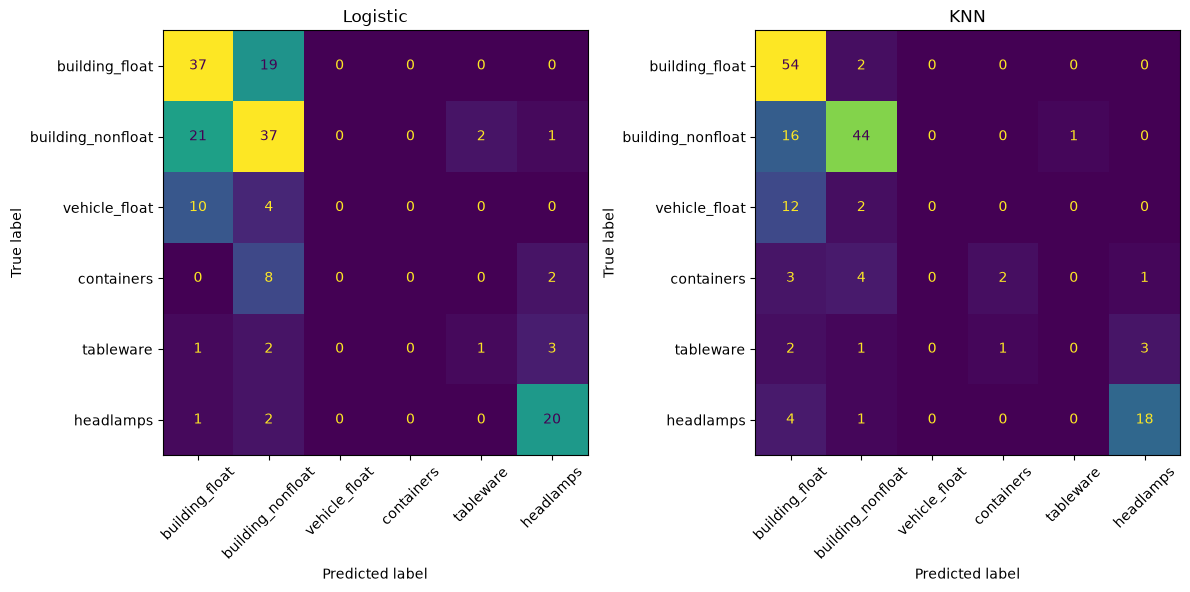

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(y_train, pred_logit, display_labels=labels, xticks_rotation=45, ax=axes[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_train, pred_knn, display_labels=labels, xticks_rotation=45, ax=axes[1], colorbar=False)
axes[0].set_title("Logistic"); axes[1].set_title("KNN")
plt.tight_layout()

KNN's extra accuracy is coming from the building float and nonfloat classes. Like I said in 3.2 it isn't the best model because it still confidently predicts incorrect answers which grows its log loss compared to the logistic model. 

c)

- KNN does better classifying building glasses (float processed and nonfloat processed), or the classes with larger amounts of observations. I think the reason it struggles mightily with the smaller variables is because with k = 15, tableware (n=7) for example is nearly guaranteed to predict another class unless their manhattan distances are all smaller (the group is distinct and packed close together). Finding more neighbors than there are observations will make KNN struggle predicting those classes.

### 3.4)

logistic: log loss = 0.9402, accuracy = 0.6744


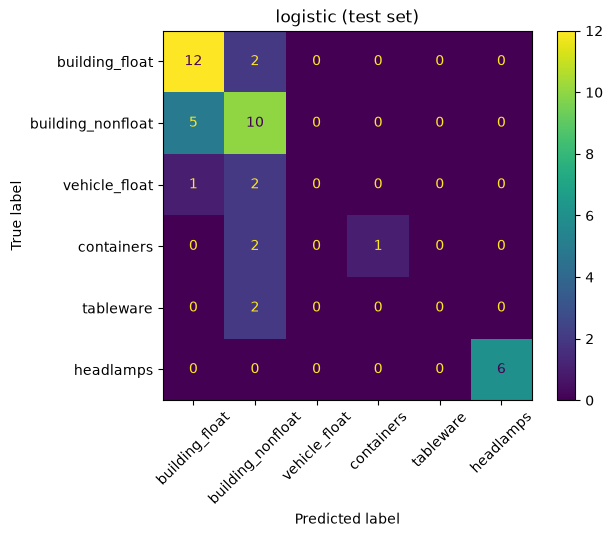

KNN: log loss = 0.7538, accuracy = 0.6279


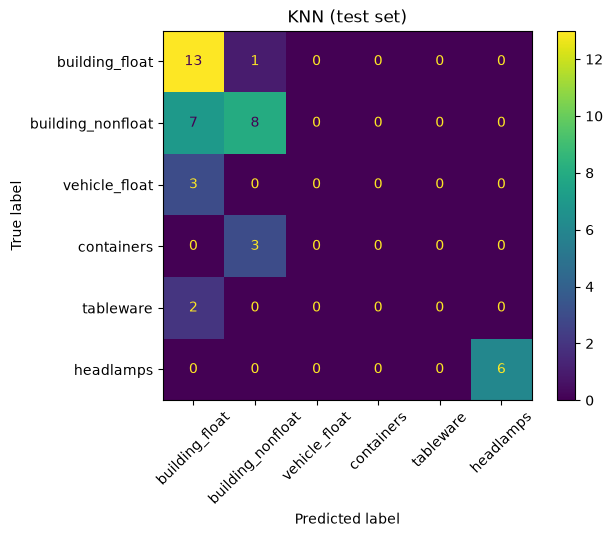

KNN zeros in test: 0


In [26]:
for name, model in [("logistic", sel_model), ("KNN", knn_best)]:
    model.fit(X_train, y_train)
    proba_test = model.predict_proba(X_test)
    pred_test = model.predict(X_test)
    print(f"{name}: log loss = {log_loss(y_test, proba_test, labels=classes):.4f}, accuracy = {accuracy_score(y_test, pred_test):.4f}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=labels, xticks_rotation=45)
    plt.title(f"{name} (test set)"); plt.show()

p_true_test = proba_test[np.arange(len(y_test)), np.searchsorted(classes, y_test)]   # proba_test is KNN's here
print("KNN zeros in test:", (p_true_test == 0).sum())

a) 
- No, in the test set the KNN model has a lower log loss (albeit lower accuracy too) which is exactly the opposite of 3.3a

b)
- You can't really conclude much about the performance on the smaller samples since it may depend heavily on which observations end up in the test set. Each fragment would add the 36.044 from 3.2 divided by the number of observations in the set, so each predicted probability 0 adds 36.044/43 in log loss